# Libraries

In [69]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import scipy as sp
from scipy import special, optimize, integrate, interpolate
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets
import copy
import time
import random
import pandas as pd
import math
import uuid
from scipy.interpolate import interp1d
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

# The magnetic fields are in a separate file.
from mag_field import Bz, Btheta, dBz, dBtheta

# Basic settings for line plots

We use Latex for matplotlib, which requires a previous installation from https://www.latex-project.org/get/.
Otherwise, the 'text.usetex' feature (enabled below) should be set to a false value.

In [70]:
%config InlineBackend.figure_format='retina' # Useful for running matplotlib on high-dpi displays.

plt.rcParams['text.usetex'] = True
plt.rc('font',**{'family':'serif','serif':['Computer Modern Roman']})
plt.rcParams.update({'font.size': 17})
plt.rcParams["figure.figsize"] = (6.5, 6)

In [71]:
def set_basics(title, axes, markzero = False):
    fig, ax = plt.subplots()
    plt.title(title)
    if markzero:
        plt.axhline(y=0, color='grey', linestyle='--', linewidth=1)
    ax.set_xlabel(axes[0])
    ax.set_ylabel(axes[1])
    return fig, ax

# NOTE: Any plot can be saved by using plt.savefig.
# dpi = 1200 corresponds to extremely high resolution.
# Example:
# plt.savefig(str(uuid.uuid4())+'.png', format="png", dpi=1200)  

# Preliminaries for the evaluation of the dispersion function

In [72]:
# PARAMETERS (normalized; don't change)
n_ite = 100
y0 = [1, 0] # Initial condition for Euler-Lagrange
R = 1
R0, Rf = 1e-3*R, (1-1e-3)*R

# AUXILIARY FUNCTIONS:

def F(r, m, k, q, zeta):
    return k*Bz(r, q, zeta) + m*Btheta(r, q, zeta)/r

def f(r, m, k, l, q, zeta):
    return r**3*(F(r, m, k, q, zeta)**2 + l)/(m**2 + (k**2)*(r**2))

def df(r, m, k, l, q, zeta):
    dF = k*dBz(r, q, zeta) + m*(dBtheta(r, q, zeta)/r - Btheta(r, q, zeta)/r**2)
    a = r**2*(F(r, m, k, q, zeta)**2 + l)*(3*m**2 + k**2*r**2)/((m**2 + k**2*r**2)**2)
    b = 2*F(r, m, k, q, zeta)*dF*r**3/(m**2 + k**2*r**2)
    return a + b

def g(r, m, k, l, q, zeta):
    den = m**2 + k**2*r**2
    a = (1-(m**2-k**2*r**2)/den**2)*r*(F(r, m, k, q, zeta)**2 + l)
    b1 = 4*m*F(r, m, k, q, zeta)*Btheta(r, q, zeta)/den
    b2 = 2*Btheta(r, q, zeta)*dBtheta(r, q, zeta) + 2*Bz(r, q, zeta)*dBz(r, q, zeta)
    b3 = 2*Btheta(r, q, zeta)**2/r*(2*F(r, m, k, q, zeta)**2/(F(r, m, k, q, zeta)**2 + l) - 1)
    b = k**2*r**2/den*(b1 + b2 + b3)
    return a - b

def F_euler(r, y, m, k, l, q, zeta):
    aux = (g(r, m, k, l, q, zeta)*y[0] - df(r, m, k, l, q, zeta)*y[1])/f(r, m, k, l, q, zeta)
    return np.array([y[1], aux])

def bound_cond_D(m, k, l, xiR, dxiR, q, zeta):
    mod2 = Bz(R, q, zeta)**2 + Btheta(R, q, zeta)**2
    aux = ((m**2 + k**2*R**2)*special.kn(m, abs(k)*R))/(abs(k)*R*special.kn(m-1, abs(k)*R) + m*special.kn(m, abs(k)*R))
    return xiR*(k**2*mod2 + l*(1+aux)) + dxiR*R*(F(R, m, k, q, zeta)**2 + l)

# Evaluating the dispersion function

In [73]:
def lineplot(x, y, axes, title, markzero = False):
    fig, ax = set_basics(title, axes, markzero)
    ax.plot(x,y)

In [74]:
# Evaluation of the dispersion function.
# If printsol = True, we plot the solution xi_r.
def disp_F(l, m, k, q, zeta, printsol = False):
    aux_euler2 = lambda y, r : F_euler(r, y, m, k, l, q, zeta)
    rr = np.linspace(R0, Rf, n_ite+1)
    sol2 = integrate.odeint(aux_euler2, y0, rr)
    xiR2, dxiR2 = sol2[-1][0], sol2[-1][1]
    if printsol:
        axes = [r'$r$', r'$\xi_r$']
        title = 'Most unstable perturbation'
        perturbation = [elem[0] for elem in sol2]
        lineplot(rr, perturbation/abs(xiR2), axes, title, markzero = True)
        print('xi(0)= ', sol2[0][0], ', xi\'(0)= ', sol2[0][1])
        print('xi(R)= ', xiR2, ', xi\'(R)= ', R*dxiR2)
    return bound_cond_D(m, k, l, xiR2, dxiR2, q, zeta)

xi(0)=  1.0 , xi'(0)=  0.0
xi(R)=  -0.05121733991249444 , xi'(R)=  -208.33066859549513
Dispersion function =  -0.03046417769322961


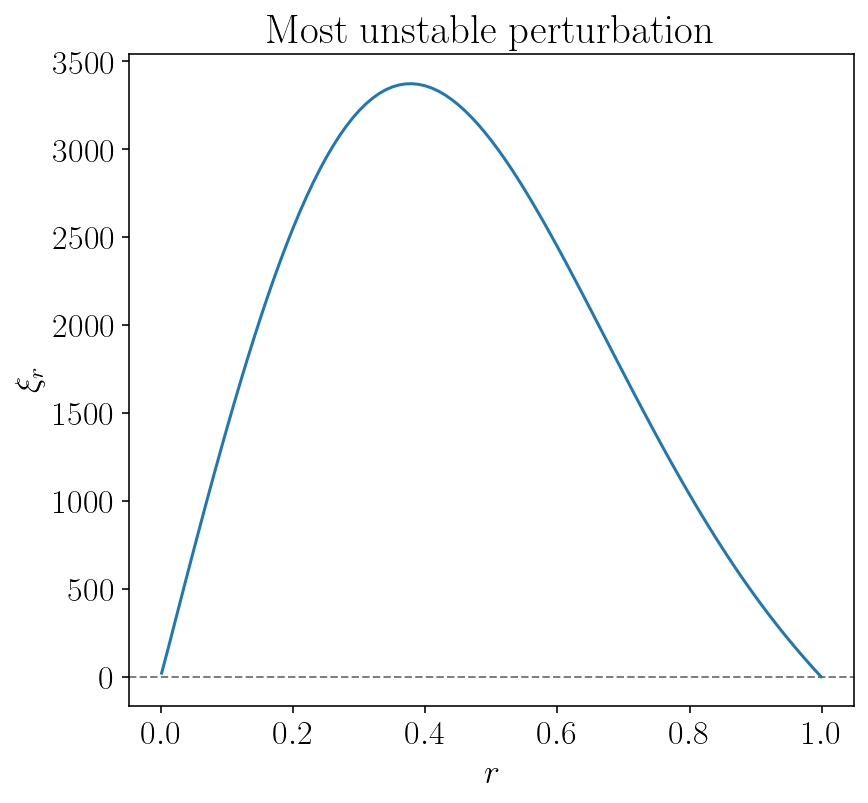

In [75]:
# How to evaluate the dispersion function D(l;k), given (zeta,q), (m,k) a value l for lambda.
# In this case, we also choose to plot the most unstable perturbation.
zeta = 1
q = 0.4
m = 2
k = -1.99*q
l = 5.29e-8
print('Dispersion function = ', disp_F(l, m, k, q, zeta, printsol = True))

# Plotting the dispersion function

In [76]:
def lineplot(x, y, axes, title, markzero = False):
    fig, ax = set_basics(title, axes, markzero)
    ax.plot(x,y)
    plt.text(0, 2.73, f'$m = {m}$', bbox=dict(boxstyle="round", ec=(0.0, 0.0, 0.0), fc=(1., 1, 1)), color = 'black')

In [77]:
def plot_dispersion_function(zeta, q, m, k, ls, normalized = True):
    D = []
    for l in ls:
        D.append(disp_F(l, m, k*q, q, zeta))
    D = D/np.mean([abs(x) for x in D]) if normalized else D
    axes = ['$\lambda$', '$D(\lambda; k)$']
    title = r'Disp. fun. for $(\zeta, q) = (%1.0f, %1.1f)$, $k/q=%1.2f$'%(zeta, q, k)
    lineplot(ls, D, axes, title, markzero = True)

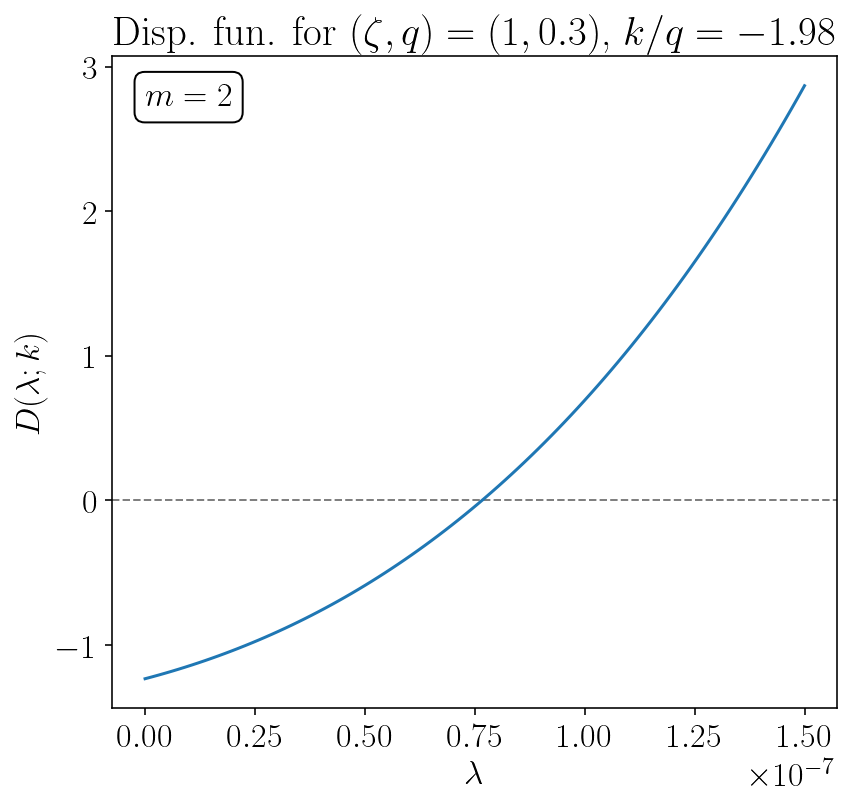

In [78]:
m=2
zeta = 1
q = 0.30
k = -1.98
lmax = 1.5e-7
lmin = 0.0005*lmax
lambdas = np.linspace(lmin,lmax,100)
plot_dispersion_function(zeta, q, m, k, lambdas)

In [79]:
def comparison_lineplot(x, ys, prelabel, labels, axes, title, posx, posy, markzero = False):
    fig, ax = set_basics(title, axes, markzero)
    for i in range(len(ys)):
        ax.plot(x[i],ys[i],label=prelabel + r' %1.3f'%(labels[i]))
    ax.legend(fancybox=True, shadow=True, facecolor='white')
    plt.legend(frameon = 1).get_frame().set_edgecolor('black')
    # The settings below are hardcoded
    ax.set_ylim([-2.2, 3.15])
    plt.text(posx, posy, f'$m = {m}$', bbox=dict(boxstyle="round", ec=(0.0, 0.0, 0.0), fc=(1., 1, 1)), color = 'black')

In [80]:
def plot_dispersion_functions(zeta, q, m, ks, ls, posx, posy):
    datax = []
    datay = []
    for k in ks:
        D = []
        for l in ls:
            D.append(disp_F(l, m, k*q, q, zeta))
        datax.append(ls)
        avg = np.mean([abs(x) for x in D]) # The dispersion function is being normalized for the comparison.
        datay.append(D/avg)
    prelabel = r'$k/q$ = '
    axes = ['$\lambda$', 'normalized $D(\lambda; k)$']
    title = r'Dispersion function for $(\zeta, q) = (%1.0f, %1.1f)$'%(zeta, q)
    comparison_lineplot(datax, datay, prelabel, ks, axes, title, posx, posy, markzero = True)

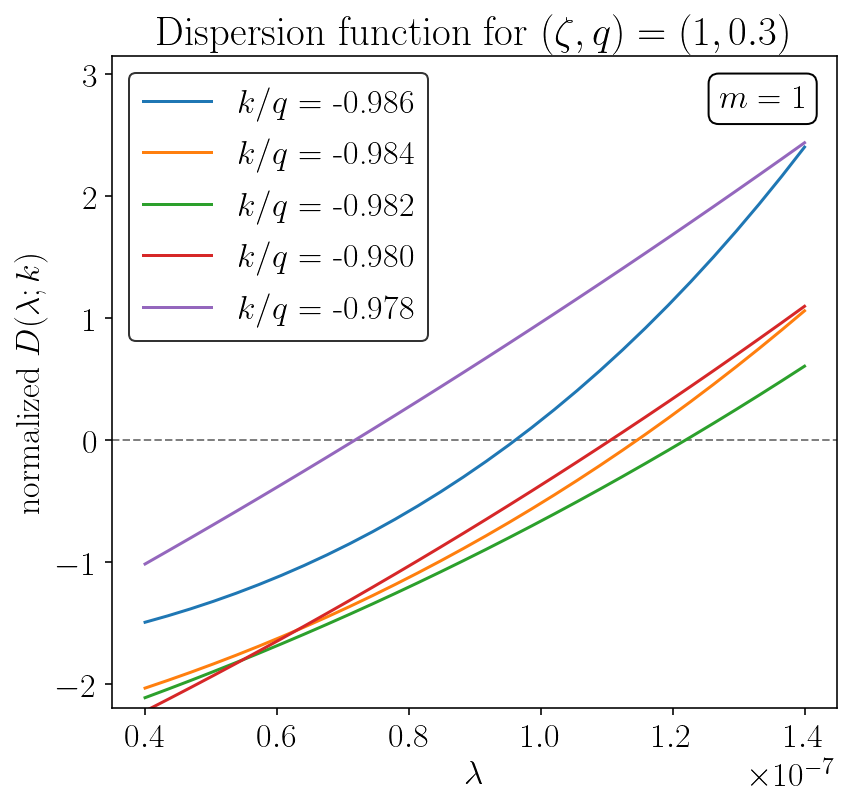

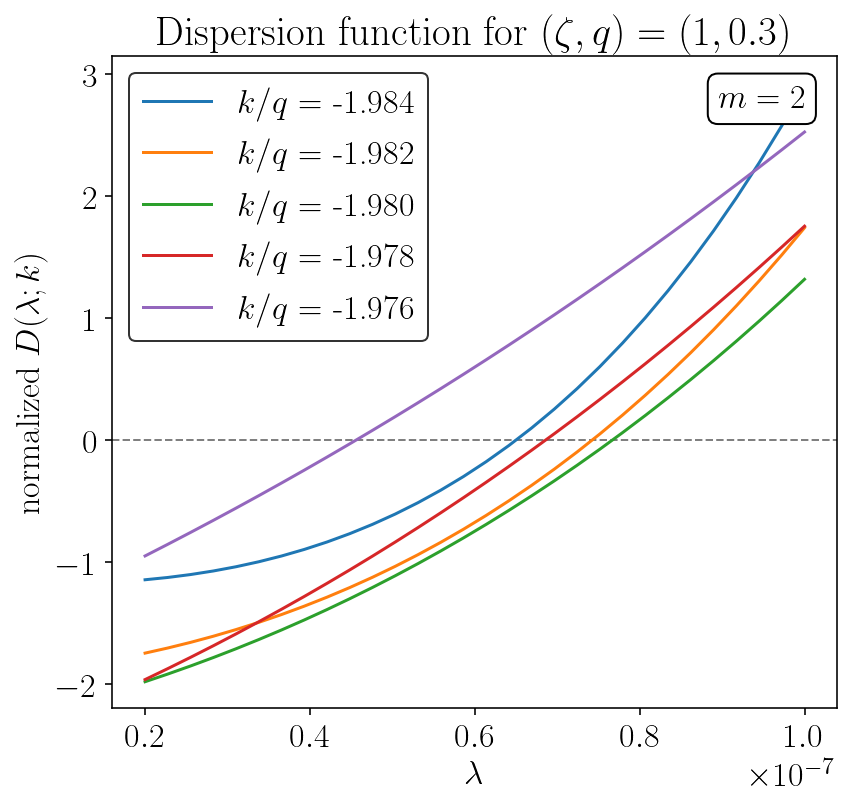

In [81]:
zeta = 1
q = 0.3
posy = 2.73

m = 1
ks = np.linspace(-0.986,-0.978,5) # Multiples of q
lambdas = np.linspace(0.4e-7,1.4e-7,30)
posx = 1.27e-7
plot_dispersion_functions(zeta, q, m, ks, lambdas, posx, posy)

m = 2
ks = np.linspace(-1.984,-1.976,5) # Multiples of q
lambdas = np.linspace(0.2e-7,1.0e-7,30)
posx = 0.895e-7
plot_dispersion_functions(zeta, q, m, ks, lambdas, posx, posy)

In [82]:
def lininterp(x0, y0, x1, y1, x2):
    m = (y1-y0)/(x1-x0)
    y2 = y1 + m*(x2-x1)
    return y2

# Finds the biggest root of a function in a given interval.
def biggest_root(func_Dlk, l_range):
    D_lk = []
    for l in l_range:
        D_lk.append(func_Dlk(l))
    all_same_sign = all(x > 0 for x in D_lk) or all(x < 0 for x in D_lk)
    if not all_same_sign:
        i = len(D_lk) - 1
        # We are only interested in finding the biggest zero.
        while np.sign(D_lk[i])*np.sign(D_lk[i-1]) > 0:
            i = i - 1
        # Linear interpolation to find the zero. We could do a dicotomic search, but it would be slower.
        return lininterp(D_lk[i-1], l_range[i-1], D_lk[i], l_range[i], 0)
    else:
        return 0

# Finds the dispersion relation between k and lambda, given the magnetic field configuration.
def dispersion_relation(zeta, q, m, k_vals, n_k, l_vals, n_l):
    ks = np.linspace(k_vals[0], k_vals[1], n_k)
    l_range = 10**(np.linspace(l_vals[0], l_vals[1], n_l)) # logarithmically spaced.
    ls = []
    for k in ks:
        D = []
        func_D = lambda l : disp_F(l, m, k, q, zeta) # Definition of a single variable function D(l).
        l = biggest_root(func_D, l_range)
        ls.append(l)
    return ks, ls

First, we look at one magnetic field configuration and several values of m. We observe that instabilities arise near k = -mq. Although we do not show it here, if q is increased one can check the range of unstable values of k becomes much wider.

In [83]:
def comparison_lineplot(x, ys, prelabel, labels, axes, title, markzero = False):
    fig, ax = set_basics(title, axes, markzero)
    for i in range(len(ys)):
        ax.plot(x[i],ys[i],label=prelabel + r' %1.0f'%(labels[i]))
    ax.legend(fancybox=True, shadow=True, facecolor='white')
    plt.legend(frameon = 1).get_frame().set_edgecolor('black')

In [84]:
def m_compare_dispersion_relation(ms, zeta, q, l_vals = [-14,-5], n_k = 60, n_l = 20):
    datax = []
    datay = []
    for m in ms:
        k_vals = [-1.3*m*q,-0.5*m*q]
        [k_range, ls] = dispersion_relation(zeta, q, m, k_vals, n_k, l_vals, n_l)
        datax.append(list(k_range/q))
        datay.append(ls)
    prelabel = r'$m$ = '
    labels = ms
    axes = ['$k/q$', '$\lambda$']
    title = r'Disp. relation for $\zeta =%1.1f$, $q =%1.1f$'%(zeta, q)
    comparison_lineplot(datax, datay, prelabel, labels, axes, title)

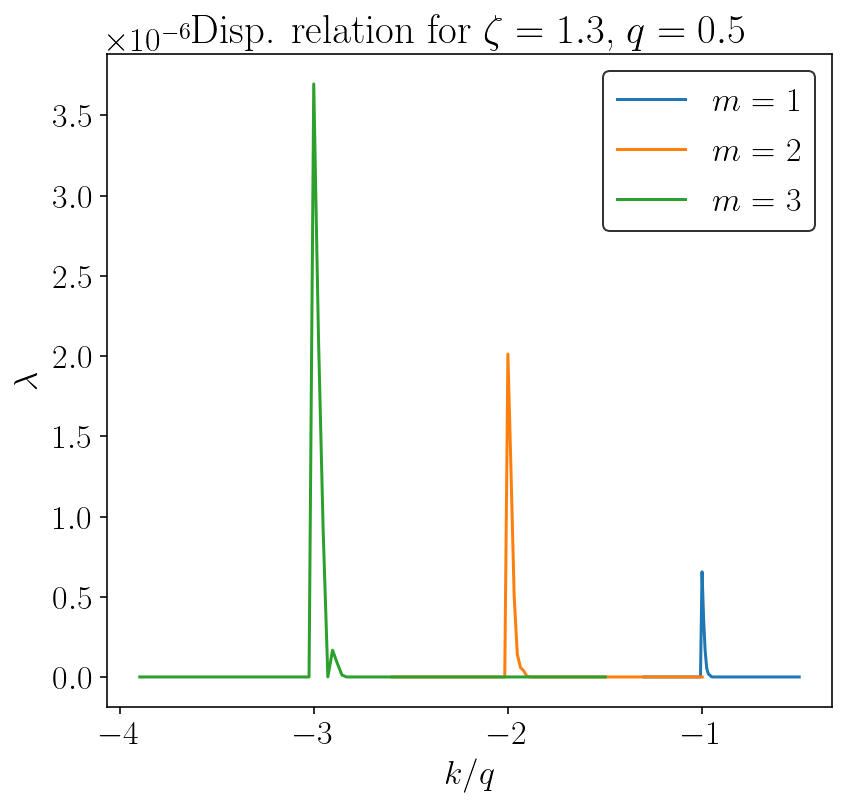

In [85]:
ms = [1,2,3]
zeta = 1.3
q = 0.5
m_compare_dispersion_relation(ms, zeta, q, l_vals = [-9,-1], n_k = 100)

Now, we fix a value of m and compare the dispersion relation for several values of q.

In [86]:
# Finds the dispersion relation for several magnetic field configurations, and plots them in the same figure.
# "eps" allows to focus in a given range of values of k, centered at -q.
# "l_vals" is the range of exponents in base 10 for lambda which is being considered to look for a solution.
# Thus, it may have to be adjusted when changing the magnetic field configuration.
# "n_k" and "n_l" can be modified to change on the degree of accuracy.
def q_compare_dispersion_relation(zeta, qs, m, posx, posy, eps = 0.05, l_vals = [-14,-5], n_k = 60, n_l = 20):
    datax = []
    datay = []
    for q in qs:
        k_vals = [-q*(m+eps/4), -q*(m-eps)]
        [k_range, ls] = dispersion_relation(zeta, q, m, k_vals, n_k, l_vals, n_l)
        datax.append(list(k_range/q))
        datay.append(ls)
    prelabel = r'$q$ = '
    labels = qs
    axes = ['$k/q$', '$\lambda$']
    title = r'Dispersion relation for $\zeta =%1.0f$'%(zeta)
    comparison_lineplot(datax, datay, prelabel, labels, axes, title, posx, posy)

In [87]:
def comparison_lineplot(x, ys, prelabel, labels, axes, title, posx, posy, markzero = False):
    fig, ax = set_basics(title, axes, markzero)
    for i in range(len(ys)):
        ax.plot(x[i],ys[i],label=prelabel + r' %1.2f'%(labels[i]))
    ax.legend(fancybox=True, shadow=True, facecolor='white')
    plt.legend(frameon = 1).get_frame().set_edgecolor('black')
    # The settings below are hardcoded
    ax.set_ylim([0, 3.2e-7])
    plt.text(posx, posy, f'$m = {m}$', bbox=dict(boxstyle="round", ec=(0.0, 0.0, 0.0), fc=(1., 1, 1)), color = 'black')

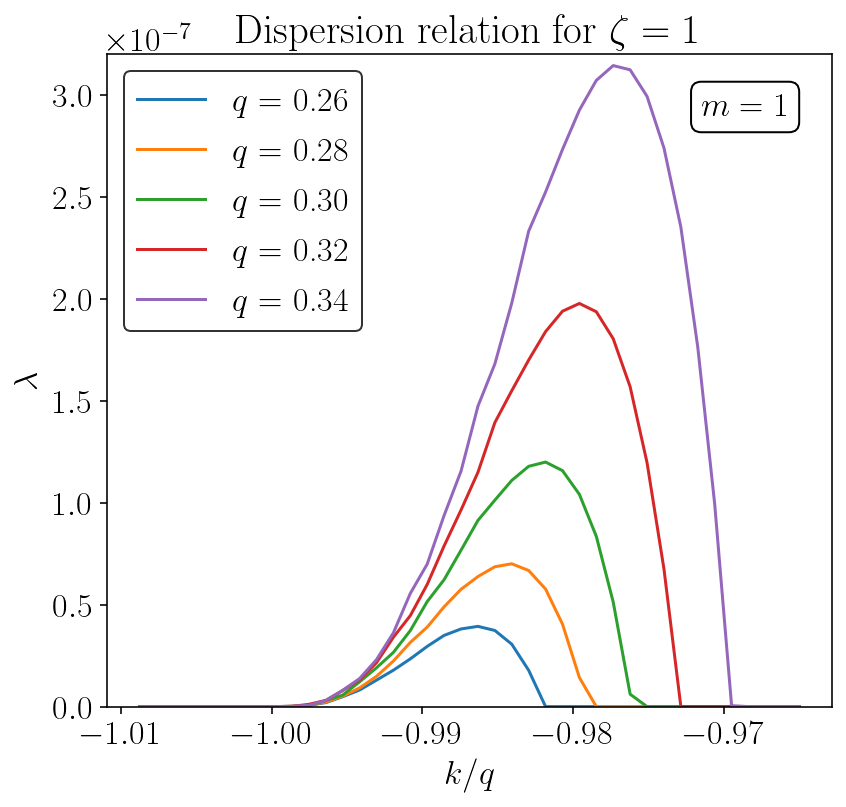

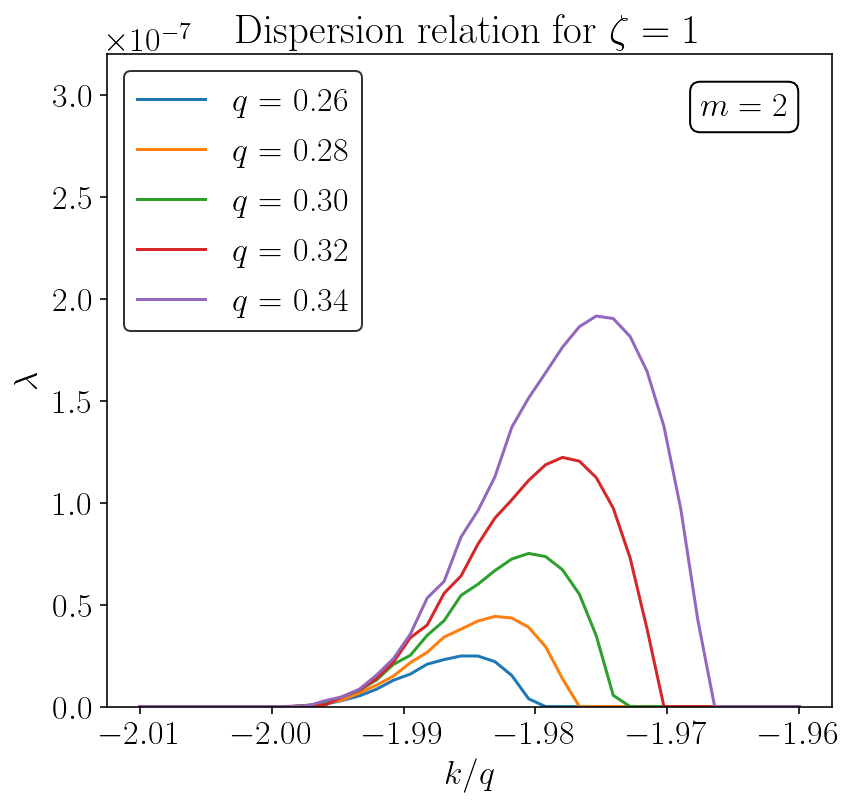

In [88]:
zeta = 1
qs = [0.26, 0.28, 0.30, 0.32, 0.34]
posy = 2.9e-7

m=1
posx = -0.9715
q_compare_dispersion_relation(zeta, qs, m, posx, posy, eps = 0.035, l_vals = [-10,-6], n_k = 40)

m = 2
posx = -1.9675
q_compare_dispersion_relation(zeta, qs, m, posx, posy, eps = 0.04, l_vals = [-10,-6], n_k = 40)

# Finding the max growth rate for each magnetic field configuration

In [89]:
def lambdamax(zeta, q, m, k_vals, n_k, l_vals, n_l):
    k_range = np.linspace(k_vals[0], k_vals[1], n_k)
    l_range = 10**(np.linspace(l_vals[0], l_vals[1], n_l)) # logarithmically spaced.
    lmax = 0
    kmax = 0
    for k in k_range:
        func_Dlk = lambda l : disp_F(l, m, k, q, zeta) # Definition of a single variable function D(l).
        l = biggest_root(func_Dlk, l_range)
        if l > lmax:
            lmax = l
            kmax = k
    return lmax, kmax

# Range of k's where we look for the maximum of the dispersion relation l(k). Could be improved.
def get_k_vals(m, q, eps = 0.05):
    return [-q*(m+eps/3), -q*(m-eps)]

In [90]:
# New cell
# Max growth rate over k, starting from the get_k_vals window. If the maximum lands on
# an edge of the window, the window is centred on that edge and the search repeated.
# Returns the best value found, its k, and the number of shifts needed.
def lambdamax_tracking(zeta, q, m, n_k, l_vals, n_l, max_shifts=10):
    k_vals = get_k_vals(m, q)
    width = k_vals[1] - k_vals[0]
    best_l, best_k = 0, 0
    for shifts in range(max_shifts + 1):
        lmax, kmax = lambdamax(zeta, q, m, k_vals, n_k, l_vals, n_l)
        if lmax > best_l:
            best_l, best_k = lmax, kmax
        if lmax == 0 or kmax not in (k_vals[0], k_vals[1]):
            return best_l, best_k, shifts
        k_vals = [kmax - width/2, kmax + width/2]
    print(f"  warning: peak not bracketed for zeta={zeta}, m={m}, q={q:.3f}")
    return best_l, best_k, shifts

In [98]:
# Max growth rate curves for Figure 5, starting from the get_k_vals window and following the peak
zeta = 1; l_vals = [-9, -3]; old_sheet = 'sheet_zeta1.csv'
#zeta = 1.5; l_vals = [-12, -3]; old_sheet = 'sheet_zeta1.5.csv'

ms = [1, 2, 3, 4]
qs = np.linspace(0.2, 0.8, 20)
n_k = 20
n_l = 20
lambdamaxs = []
n_shifts = []
for m in ms:
    this_curve = []
    these_shifts = []
    print('Obtaining curve for m =', m)
    for q in qs:
        l, k, s = lambdamax_tracking(zeta, q, m, n_k, l_vals, n_l)
        this_curve.append(l)
        these_shifts.append(s)
        print(f'For q = {q:.3f}, lambda = {l:.3e}  (k/q = {k/q:.3f}, shifts = {s})')
    print('')
    lambdamaxs.append(this_curve)
    n_shifts.append(these_shifts)

np.savetxt(f'sheet_zeta{zeta}_new.csv', lambdamaxs, delimiter=',')

Obtaining curve for m = 1
For q = 0.200, lambda = 0.000e+00  (k/q = 0.000, shifts = 0)
For q = 0.232, lambda = 0.000e+00  (k/q = 0.000, shifts = 0)
For q = 0.263, lambda = 1.681e-12  (k/q = -0.999, shifts = 0)
For q = 0.295, lambda = 1.351e-09  (k/q = -0.999, shifts = 0)
For q = 0.326, lambda = 1.409e-08  (k/q = -0.999, shifts = 0)
For q = 0.358, lambda = 4.953e-08  (k/q = -0.999, shifts = 0)
For q = 0.389, lambda = 1.378e-07  (k/q = -0.999, shifts = 0)
For q = 0.421, lambda = 3.108e-07  (k/q = -0.999, shifts = 0)
For q = 0.453, lambda = 4.625e-07  (k/q = -0.999, shifts = 0)
For q = 0.484, lambda = 9.264e-07  (k/q = -0.999, shifts = 0)
For q = 0.516, lambda = 1.268e-06  (k/q = -0.999, shifts = 0)
For q = 0.547, lambda = 1.825e-06  (k/q = -0.999, shifts = 0)
For q = 0.579, lambda = 2.838e-06  (k/q = -0.999, shifts = 0)
For q = 0.611, lambda = 3.544e-06  (k/q = -0.999, shifts = 0)
For q = 0.642, lambda = 4.081e-06  (k/q = -0.999, shifts = 0)
For q = 0.674, lambda = 5.721e-06  (k/q = -0.9

In [99]:
# Sanity checks of the new curves
old = np.loadtxt(old_sheet, delimiter=',')
new = np.array(lambdamaxs)
shifts = np.array(n_shifts)

# 1. Where no shift was needed the search is the original one, so it must reproduce the old sheet
same = shifts == 0
rel = np.abs(new[same] - old[same]) / np.where(old[same] > 0, old[same], 1)
print(f'1. Unshifted points: {same.sum()} of {new.size}, max relative difference to old sheet = {rel.max() if rel.size else 0:.2e}')

# 2. The search starts from the old window and keeps the best value, so it can never be lower
print(f'2. Points where new < old: {(new < old*(1 - 1e-9)).sum()}')

# 3. lambda_max should not drop as q increases
for i, m in enumerate(ms):
    d = np.diff(new[i]) / np.where(new[i][:-1] > 0, new[i][:-1], 1)
    print(f'3. m = {m}: largest drop between consecutive q = {min(d.min(), 0):.1%}')

# 4. Independent check against the wide k search run earlier (zeta = 1 only)
if zeta == 1:
    print(f'4. q = 0.8: m = 1 new {new[0,-1]:.3e} vs wide search 1.490e-04,  '
          f'm = 2 new {new[1,-1]:.3e} vs wide search 5.912e-05')

1. Unshifted points: 80 of 80, max relative difference to old sheet = 2.71e-07
2. Points where new < old: 16
3. m = 1: largest drop between consecutive q = 0.0%
3. m = 2: largest drop between consecutive q = 0.0%
3. m = 3: largest drop between consecutive q = 0.0%
3. m = 4: largest drop between consecutive q = 0.0%


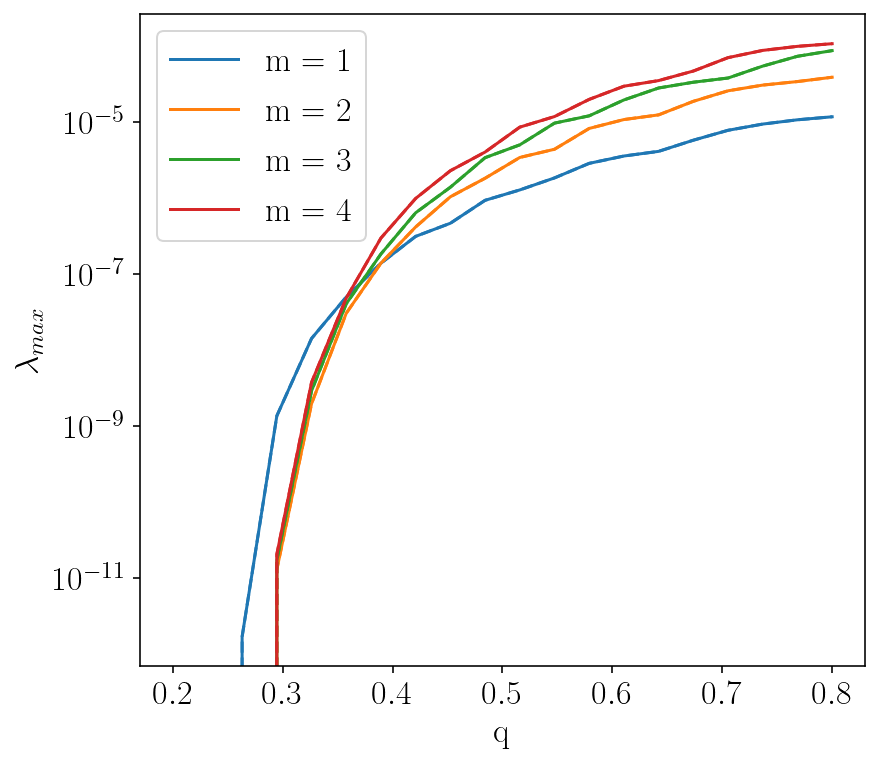

In [100]:
# Old (dashed) vs new (solid) maximum growth rates
for i, m in enumerate(ms):
    plt.semilogy(qs, old[i], '--', color=f'C{i}')
    plt.semilogy(qs, new[i], '-', color=f'C{i}', label=f'm = {m}')
plt.xlabel('q')
plt.ylabel(r'$\lambda_{max}$')
plt.legend()
plt.savefig(f'lambdamax_old_vs_new_zeta{zeta}.png', dpi=200, bbox_inches='tight')
plt.show()

In [101]:
ms = [1,2,3,4]
qs = np.linspace(0.2, 0.8, 20)

The cell below should be executed for both zeta = 1 and zeta = 1.5. The execution process is slow, so the results are saved into an excel sheet. This has already been done, and the excel sheets have been renamed to 'sheet_zeta1.csv' and 'sheet_zeta1.5.csv' respectively. Hence, there is no need to execute the cell below to obtain the plots shown in the thesis. However, it can be used to obtain similar plots, varying the value of zeta, de values of m, etc.

In [23]:
"""
zeta = 1; l_vals = [-9,-3];
#zeta = 1.5; l_vals = [-12,-3];

n_k = 20
n_l = 20
lambdamaxs = []
for m in ms:
    this_curve = []
    print('Obtaining curve for m =', m)
    for q in qs:
        k_vals = get_k_vals(m, q)
        l = lambdamax(zeta, q, m, k_vals, n_k, l_vals, n_l)[0]
        this_curve.append(l)
        print(r'For q = ' + str(np.round(q,3)) + ', lambda = ' + str(l))
    print('')
    lambdamaxs.append(this_curve)
    
# Save as csv
np.savetxt('sheet_'+str(uuid.uuid4())+'.csv', lambdamaxs, delimiter=',')
"""

"\nzeta = 1; l_vals = [-9,-3];\n#zeta = 1.5; l_vals = [-12,-3];\n\nn_k = 20\nn_l = 20\nlambdamaxs = []\nfor m in ms:\n    this_curve = []\n    print('Obtaining curve for m =', m)\n    for q in qs:\n        k_vals = get_k_vals(m, q)\n        l = lambdamax(zeta, q, m, k_vals, n_k, l_vals, n_l)[0]\n        this_curve.append(l)\n        print(r'For q = ' + str(np.round(q,3)) + ', lambda = ' + str(l))\n    print('')\n    lambdamaxs.append(this_curve)\n    \n#\xa0Save as csv\nnp.savetxt('sheet_'+str(uuid.uuid4())+'.csv', lambdamaxs, delimiter=',')\n"

In [102]:
# Load the max growth rate data from the re-named csv sheets
data1 = np.loadtxt('sheet_zeta1.csv', delimiter=',')
data2 = np.loadtxt('sheet_zeta1.5.csv', delimiter=',')

In [103]:
def comparison_lineplot(x, ys, prelabel, labels, axes, title, markzero = False):
    fig, ax = set_basics(title, axes, markzero)
    for i in range(len(ys)):
        ax.plot(x[i],ys[i],label=prelabel + r' %1.0f'%(labels[i]))
    ax.legend(fancybox=True, shadow=True, facecolor='white')
    plt.legend(frameon = 1).get_frame().set_edgecolor('black')
    # The settings below are hardcoded
    plt.grid()
    ax.set_yscale('log')
    ax.set_ylim([1e-9, 2e-4])

In [104]:
def max_growth_plot(datay, zeta):
    datax = [qs, qs, qs, qs]
    datay = datay
    prelabel = r'$m$ = '
    labels = ms
    axes = [r'$q$', r'$\lambda_{max}$']
    title = 'Max. growth rate comparison'
    title = r'Max. growth rate comparison for $\zeta =%1.1f$'%(zeta)
    comparison_lineplot(datax, datay, prelabel, labels, axes, title)

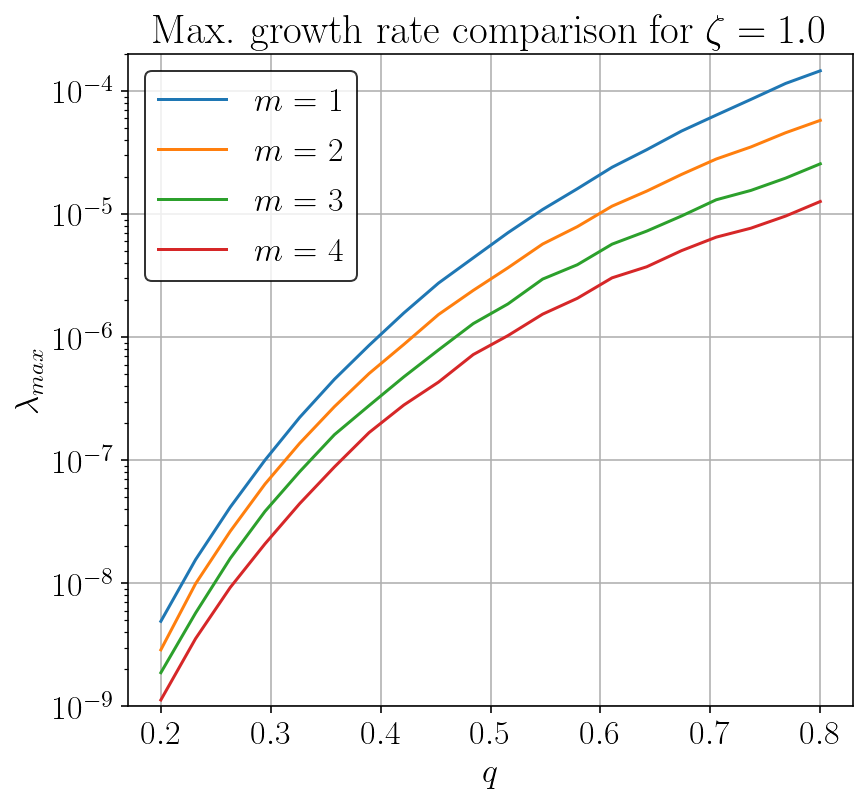

In [105]:
max_growth_plot(data1, 1)

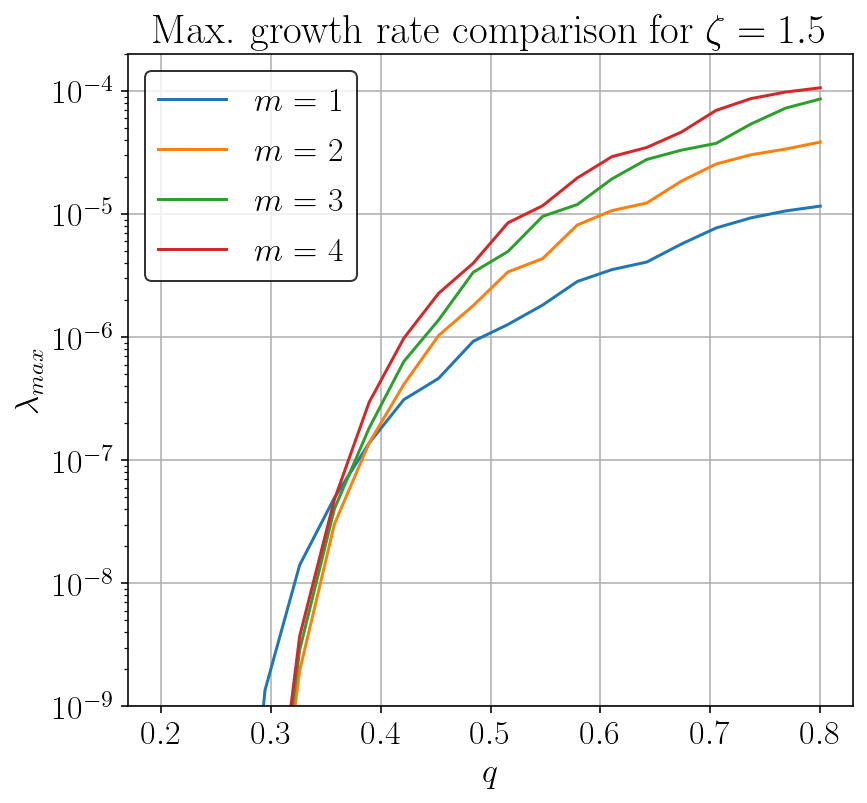

In [106]:
max_growth_plot(data2, 1.5)

In [109]:
# Saving combined figure for article.

#max_growth_plot(data1, 1)
#plt.savefig('fig5_left.png', dpi=300, bbox_inches='tight')

#max_growth_plot(data2, 1.5)
#ax = plt.gca()
#ax.set_ylabel('')
#ax.tick_params(which='both', labelleft=False)
#plt.savefig('fig5_right.png', dpi=300, bbox_inches='tight')

#from PIL import Image
#left = Image.open('fig5_left.png').convert('RGB')
#right = Image.open('fig5_right.png').convert('RGB')
#[gap, height] = [40, max(left.height, right.height)]
#fig5 = Image.new('RGB', (left.width + gap + right.width, height), 'white')
#fig5.paste(left, (0, height - left.height))
#fig5.paste(right, (left.width + gap, height - right.height))
#fig5.save('fig5.png', dpi=(300, 300))

# Finding the "critical q" for each zeta, given a threshold l0

In [29]:
def critical_q(zeta, l0, qmin, qmax, eps = 0.05, tol = 0.01, n_k = 20, n_l = 10):
    l_vals = [np.log10(l0)-0.5, np.log10(l0)+0.5]
    while (qmax - qmin > tol):
        #print(round(qmin,2), round(qmax,2))
        qmid = (qmin + qmax)/2
        k_vals = get_k_vals(m, qmid, eps = eps)
        lmid = lambdamax(zeta, qmid, m, k_vals, n_k, l_vals, n_l)[0]
        if (lmid < l0):
            qmin = qmid
        else:
            qmax = qmid
    q = (qmin + qmax)/2
    return q

In [30]:
m = 1
zeta = 1
l0 = 1e-7
[qmin, qmax] = [0.2, 0.8]
q = critical_q(zeta, l0, qmin, qmax)
print('Instability: m =', m)
print('Threshold: l0 =', l0)
print('Force parameter: zeta =', zeta)
print('Critical twist parameter: q =', q)

Instability: m = 1
Threshold: l0 = 1e-07
Force parameter: zeta = 1
Critical twist parameter: q = 0.2984375


In [31]:
# Determines a numpy array of values of zeta, spaced so that the plot looks nice.
def obtain_zetas(N = 30, zeta_min = 1, zeta_1 = 1.05, zeta_2 = 1.2, zeta_max = 1.5):
    a1 = np.linspace(zeta_min, zeta_1, int(N/3))
    a2 = np.linspace(zeta_1 + (zeta_2 - zeta_1)*3/N, zeta_2, int(N/3))
    a3 = np.linspace(zeta_2 + (zeta_max - zeta_2)*3/N, zeta_max, int(N/3))
    return np.concatenate((a1,a2,a3))

# Plot 4a: different thresholds

Again, the cell below takes time to execute, but the results have already been conveniently saved into the 'm1.csv' spreadsheet, so they can be used immediately to obtain the plots. Hence, there is no need to execute this cell.

In [32]:
"""
# Small zetas
m = 1
zetas = obtain_zetas()
ls = [4e-8, 7e-8, 1e-7]
qs = [[0.20, 0.55], [0.25, 0.60], [0.25, 0.60]]

crit_qs = []
for i in range(len(ls)):
    this_curve = []
    print('Obtaining curve for lambda =', ls[i])
    for zeta in zetas:
        q = critical_q(zeta, ls[i], qs[i][0], qs[i][1], tol = 0.002)
        this_curve.append(q)
        print(r'For zeta = ' + str(np.round(zeta,3)) + ', q = ' + str(np.round(q,3)))
    print('')
    crit_qs.append(this_curve)
np.savetxt('sheet_'+str(uuid.uuid4())+'.csv', crit_qs, delimiter=',')
"""

"\n#\xa0Small zetas\nm = 1\nzetas = obtain_zetas()\nls = [4e-8, 7e-8, 1e-7]\nqs = [[0.20, 0.55], [0.25, 0.60], [0.25, 0.60]]\n\ncrit_qs = []\nfor i in range(len(ls)):\n    this_curve = []\n    print('Obtaining curve for lambda =', ls[i])\n    for zeta in zetas:\n        q = critical_q(zeta, ls[i], qs[i][0], qs[i][1], tol = 0.002)\n        this_curve.append(q)\n        print(r'For zeta = ' + str(np.round(zeta,3)) + ', q = ' + str(np.round(q,3)))\n    print('')\n    crit_qs.append(this_curve)\nnp.savetxt('sheet_'+str(uuid.uuid4())+'.csv', crit_qs, delimiter=',')\n"

In [33]:
def comparison_lineplot(x, ys, prelabel, labels, axes, title, markzero = False):
    fig, ax = set_basics(title, axes, markzero)
    for i in range(len(ys)):
        ax.plot(x[i],ys[i],label=prelabel + "{:.0e}".format(labels[i]))
    ax.legend(fancybox=True, shadow=True)
    plt.legend(frameon = 1).get_frame().set_edgecolor('black')
    plt.text(1.438, 0.267, f'$m = {m}$', bbox=dict(boxstyle="round", ec=(0.0, 0.0, 0.0), fc=(1., 1, 1)), color = 'black')
    ax.set_ylim([0.25, 0.58])

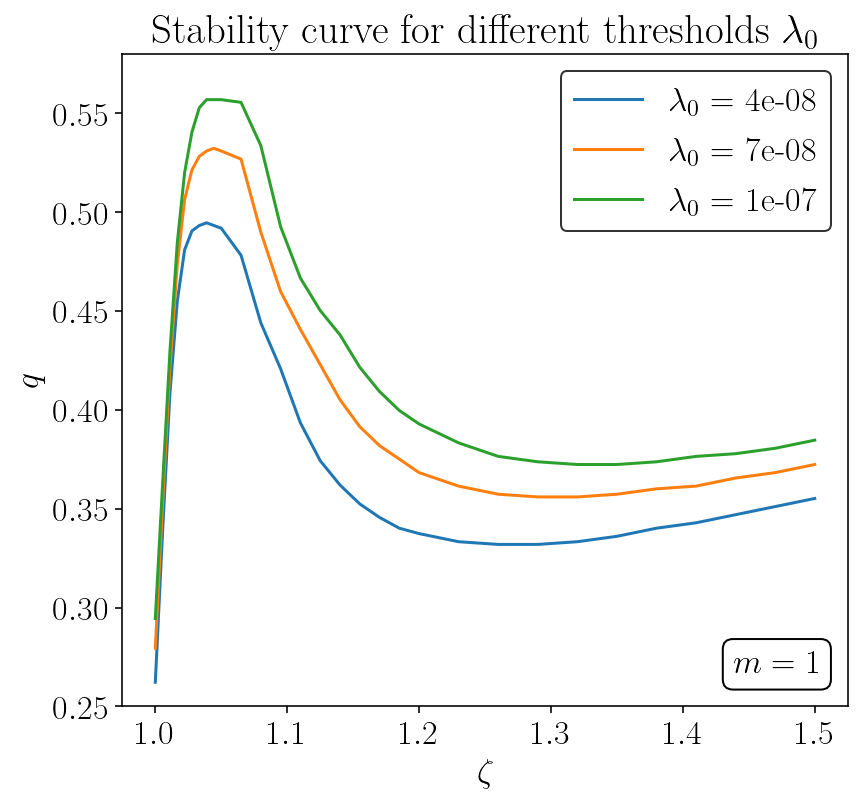

In [34]:
m = 1
datax = [obtain_zetas(), obtain_zetas(), obtain_zetas()]
datay = np.loadtxt('sheet_m1.csv', delimiter=',')
prelabel = r'$\lambda_0$ = '
labels = [4e-8, 7e-8, 1e-7]
axes = [r'$\zeta$', r'$q$']
title = 'Stability curve for different thresholds $\lambda_0$'
comparison_lineplot(datax, datay, prelabel, labels, axes, title)
#     ax.ticklabel_format(style='plain')

# Plot 4b: different m's

The cell below is the last of the cells that take so much time to execute. The results have been previously saved to 'l1e-7.csv'.

In [35]:
"""
# Small zetas
l = 1e-7
zetas = obtain_zetas()
ms = [1, 2, 3]
qs = [[0.25, 0.60], [0.2, 0.75], [0.2, 0.5]]
crit_qs = []
for i in range(len(ms)):
    this_curve = []
    m = ms[i]
    print('Obtaining curve for m =', m)
    for zeta in zetas:
        q = critical_q(zeta, l, qs[i][0], qs[i][1], tol = 0.002)
        this_curve.append(q)
        print(r'For zeta = ' + str(np.round(zeta,3)) + ', q = ' + str(np.round(q,3)))
    print('')
    crit_qs.append(this_curve)
np.savetxt('sheet_'+str(uuid.uuid4())+'.csv', crit_qs, delimiter=',')
"""

"\n#\xa0Small zetas\nl = 1e-7\nzetas = obtain_zetas()\nms = [1, 2, 3]\nqs = [[0.25, 0.60], [0.2, 0.75], [0.2, 0.5]]\ncrit_qs = []\nfor i in range(len(ms)):\n    this_curve = []\n    m = ms[i]\n    print('Obtaining curve for m =', m)\n    for zeta in zetas:\n        q = critical_q(zeta, l, qs[i][0], qs[i][1], tol = 0.002)\n        this_curve.append(q)\n        print(r'For zeta = ' + str(np.round(zeta,3)) + ', q = ' + str(np.round(q,3)))\n    print('')\n    crit_qs.append(this_curve)\nnp.savetxt('sheet_'+str(uuid.uuid4())+'.csv', crit_qs, delimiter=',')\n"

In [36]:
def comparison_lineplot(x, ys, prelabel, labels, axes, title, markzero = False):
    fig, ax = set_basics(title, axes, markzero)
    colors = [u'#2ca02c', u'#ff7f0e', u'#1f77b4'] # inverted color cycle, to match the green line in the previous
    for i in range(len(ys)):
        ax.plot(x[i],ys[i],label=prelabel + r' %1.0f'%(labels[i]), color = colors[i])
    ax.legend(fancybox=True, shadow=True)
    plt.legend(frameon = 1).get_frame().set_edgecolor('black')
    plt.text(1.394, 0.267, r"$\lambda_0$ = {:.0e}".format(l), bbox=dict(boxstyle="round", ec=(0.0, 0.0, 0.0), fc=(1., 1, 1)), color = 'black')
    ax.set_ylim([0.25, 0.58])

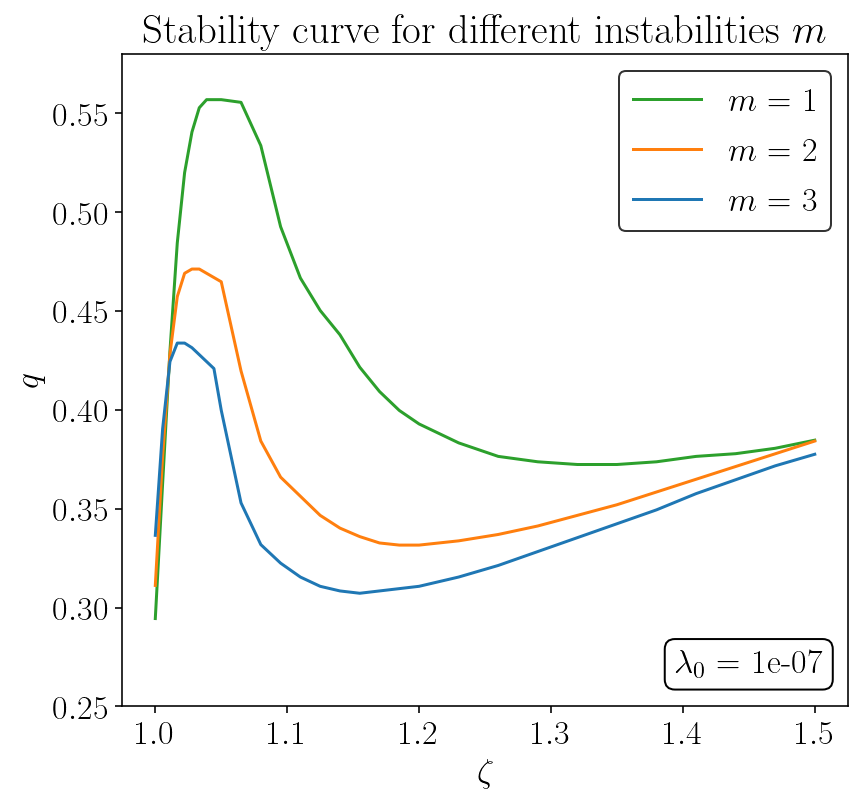

In [37]:
l = 10**(-7)
datax = [obtain_zetas(), obtain_zetas(), obtain_zetas()]
datay = np.loadtxt('sheet_l1e-7.csv', delimiter=',')
prelabel = r'$m$ = '
labels = [1, 2, 3]
axes = [r'$\zeta$', r'$q$']
title = 'Stability curve for different instabilities $m$'
comparison_lineplot(datax, datay, prelabel, labels, axes, title)

# Combining stability plots with twist and Lorentz forces

In [38]:
import matplotlib.patheffects as mpe

def line_colorplot(xi, yi, Z, label, ticks, cmap, x, ys, prelabel, labels, axes): 
    fig, ax = plt.subplots()
    plt.rcParams["figure.figsize"] = (6.5, 7.5)
    ax.set_xlabel(axes[0])
    ax.set_ylabel(axes[1])
    # Contourf:
    xi = np.array(xi); yi = np.array(yi); Z = np.array(Z)
    X, Y = np.meshgrid(xi, yi)
    im = plt.contourf(X, Y, Z, 100, cmap=plt.get_cmap(cmap))
    cb = plt.colorbar(im , ax = [ax], location = 'top', label=label)
    cb.set_ticks(ticks) 
    
    # Lines:
    #colors = [u'#2ca02c', u'#ff7f0e', u'#1f77b4'] # inverted color cycle, to match the green line in the previous
    pe1 = [mpe.Stroke(linewidth=3, foreground='black'), mpe.Stroke(foreground='black',alpha=1),mpe.Normal()]
    for i in range(len(ys)):
        ax.plot(x[i],ys[i],label=prelabel + r' %1.0f'%(labels[i]), linewidth = 2.3, path_effects=pe1)
    ax.legend(fancybox=True, shadow=True)
    plt.legend(frameon = 1).get_frame().set_edgecolor('black')
    ax.set_ylim([0.25, 0.58])
    plt.show()

In [39]:
# Lines that will be plotted
l = 10**(-7)
datax = [obtain_zetas(), obtain_zetas(), obtain_zetas()]
datay = np.loadtxt('sheet_l1e-7.csv', delimiter=',')
prelabel = r'$m$ = '
labels = [1, 2, 3]
axes = [r'$\zeta$', r'$q$']

In [40]:
N = 20
rr = np.linspace(0.01,1,100)
a = np.linspace(1,1.5,N)
q = np.linspace(0.25,0.58,N)

In [41]:
def Lorentz(a, q, r):
    mu0 = 1
    return (2*q**2*r)/(mu0*(q**2*r**2 + 1)**3) - (q*r**a*((q*r**a)/(q**2*r**2 + 1) - (2*q**3*r**a*r**2)/(q**2*r**2 + 1)**2 + (a*q*r*r**(a - 1))/(q**2*r**2 + 1)))/(mu0*r*(q**2*r**2 + 1))

def Twist(a, q, r):
    return q*r**(a-1)

def avg(f, param1, param2):
    rr = np.linspace(0.01,1,100)
    return np.mean(2*np.multiply(rr, np.abs(f(param1, param2, rr))))

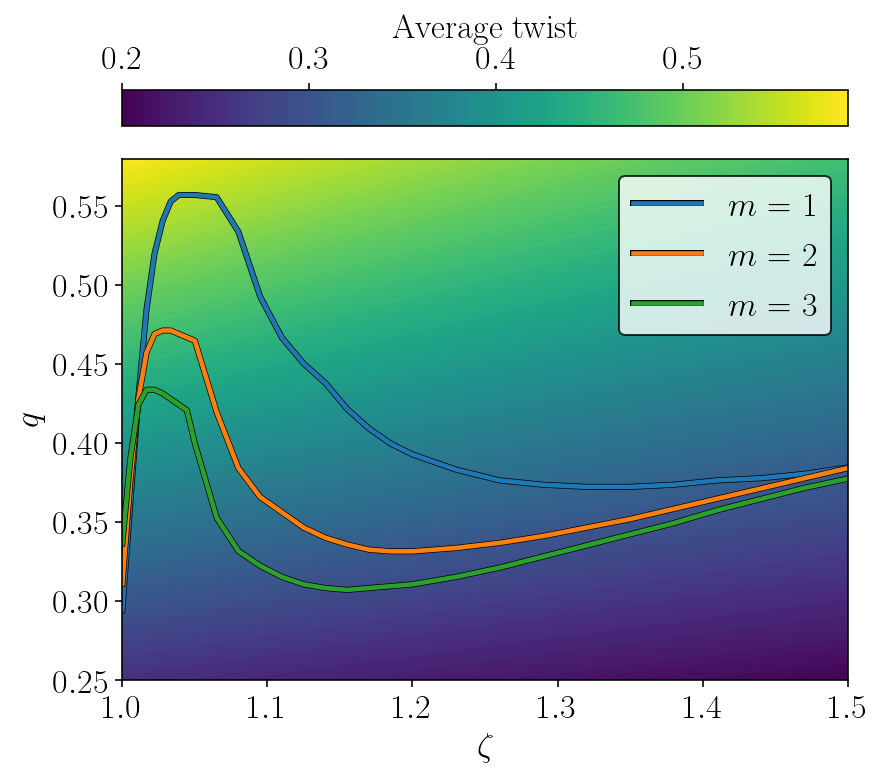

In [42]:
# Twist
Z = np.empty((N, N))
for i in range(N):
    for j in range(N):
        Z[i][j] = avg(Twist, a[j], q[i])
label = 'Average twist'
ticks = np.linspace(0,1,11)
cmap = 'viridis'
line_colorplot(a, q, Z, label, ticks, cmap, datax, datay, prelabel, labels, axes)

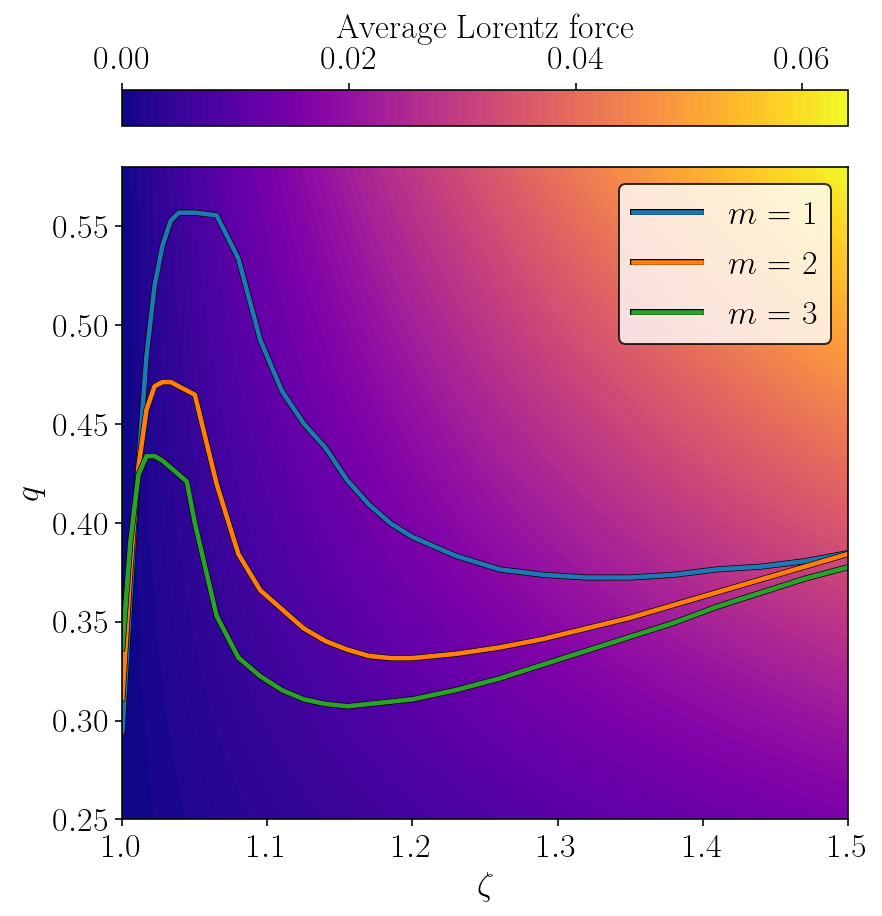

In [43]:
# Lorentz
Z = np.empty((N, N))
for i in range(N):
    for j in range(N):
        Z[i][j] = avg(Lorentz, a[j], q[i])
label = 'Average Lorentz force'
ticks = np.linspace(0,0.2,11)
cmap = 'plasma'
line_colorplot(a, q, Z, label, ticks, cmap, datax, datay, prelabel, labels, axes)